# Análise Exploratória de Dados (EDA) e Rede Neural de Recomendação de Benefícios (Agente A2 — SinergIA)

Este notebook apresenta a **Análise Exploratória de Dados (EDA)** completa e o **Treinamento da Rede Neural MLP (`Multi-Layer Perceptron`)** da funcionalidade **F2 (Direitos e Benefícios)** do **Agente A2 (Bem-Estar)**.

### Objetivos da EDA para a Rede Neural
1. **Auditoria de Qualidade e Governança LGPD (Art. 6º, III e Art. 11):** Verificar a integridade dos **740 registros reais** da base brasileira *Absenteeism at Work* (*UCI Machine Learning Repository — ID 445*) e comprovar o bloqueio integral de dados clínicos/sensíveis (`CID`, `IMC`, `peso`, `tabagismo/álcool`) e punitivos (`falhas disciplinares`).
2. **Análise Univariada e Escala das Features de Entrada ($X$):** Inspecionar a distribuição de `idade`, `tempo_empresa`, `dependentes` e `carga_trabalho` (índice **NASA-TLX**), demonstrando matematicamente por que a **Normalização Z-score** (calculada exclusivamente no treino para evitar *Data Leakage*) é indispensável para convergir os pesos da camada `nn.Linear(4, 8)`.
3. **Análise Multirrótulo dos Benefícios ($Y$) e Baseline:** Quantificar a prevalência histórica dos 5 benefícios e a **cardinalidade multirrótulo** (média de **2,82 benefícios simultâneos por colaborador**), justificando o uso de `nn.Sigmoid()` + `nn.BCELoss()` em vez de `Softmax`, o corte **Top-3** e a origem exata do **Baseline de Popularidade (`52,7%`)**.
4. **Análise Bivariada e Correlações ($X \times Y$):** Mapear como cada variável administrativa impulsiona ou reduz a propensão de adesão a cada benefício antes do treinamento não-linear.

In [1]:
import csv
from pathlib import Path
import torch
import torch.nn as nn
import torch.optim as optim

# 1. CARREGAMENTO E AUDITORIA DE INTEGRIDADE DA BASE REAL UCI (ID 445)
caminho_csv = Path.cwd().resolve().parents[3] / "data" / "uci" / "Absenteeism_at_work.csv"
if not caminho_csv.exists():
    caminho_csv = Path.cwd().resolve() / "data" / "uci" / "Absenteeism_at_work.csv"

with open(caminho_csv, mode="r", encoding="utf-8") as arquivo:
    leitor = csv.reader(arquivo, delimiter=";")
    cabecalho = [col.strip() for col in next(leitor)]
    linhas_brutas = list(leitor)

n_linhas = len(linhas_brutas)
n_colunas = len(cabecalho)
valores_nulos = sum(1 for linha in linhas_brutas for v in linha if v.strip() == "")
linhas_uci = [[float(valor) for valor in linha] for linha in linhas_brutas]
ids_unicos = len({int(linha[0]) for linha in linhas_uci})

print("=== 1. AUDITORIA ESTRUTURAL E GOVERNANÇA LGPD (BASE UCI) ===")
print(f"Total de registros (linhas): {n_linhas} | Total de variáveis (colunas): {n_colunas}")
print(f"Valores ausentes (nulos/NaN): {valores_nulos} (0.0%) | Perfis únicos (ID): {ids_unicos}")
print("\n[Governança LGPD - Art. 6º III (Minimização) e Art. 11 (Dados Sensíveis)]")
print(" -> Features de Entrada (X) [4 col. administrativas]: Age (8), Service time (7), Son (13), Work load Average/day (9)")
print(" -> Variáveis Auxiliares de Rotina (Y) [3 col. logísticas]: Distance (6), Transportation expense (5), Education (12)")
print(" -> Colunas Bloqueadas (NUNCA entram em X ou Y): Reason for absence/CID (1), Disciplinary failure (11),")
print("    Social drinker (14), Social smoker (15), Weight (17), Body mass index/IMC (19), Absenteeism hours (20)")

=== 1. AUDITORIA ESTRUTURAL E GOVERNANÇA LGPD (BASE UCI) ===
Total de registros (linhas): 740 | Total de variáveis (colunas): 21
Valores ausentes (nulos/NaN): 0 (0.0%) | Perfis únicos (ID): 36

[Governança LGPD - Art. 6º III (Minimização) e Art. 11 (Dados Sensíveis)]
 -> Features de Entrada (X) [4 col. administrativas]: Age (8), Service time (7), Son (13), Work load Average/day (9)
 -> Variáveis Auxiliares de Rotina (Y) [3 col. logísticas]: Distance (6), Transportation expense (5), Education (12)
 -> Colunas Bloqueadas (NUNCA entram em X ou Y): Reason for absence/CID (1), Disciplinary failure (11),
    Social drinker (14), Social smoker (15), Weight (17), Body mass index/IMC (19), Absenteeism hours (20)

---
## 2. Estatísticas Descritivas das Variáveis de Entrada ($X$) e Efeito da Escala

Antes de alimentar a camada oculta `nn.Linear(4, 8)`, analisamos a distribuição estatística das 4 variáveis de entrada ($X$) e das 3 variáveis logísticas auxiliares, bem como a estabilidade entre a partição de **Treino (80% = 592 registros)** e **Teste (20% = 148 registros)**:

| Variável | Papel | Média Geral | Desvio Padrão | Mínimo | Q25 (25%) | Mediana (50%) | Q75 (75%) | Máximo | Média Treino (592) | Média Teste (148) |
| :--- | :--- | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: | :---: |
| **`idade`** (`Age`) | Entrada $X_1$ | 36,45 | 6,48 | 27,0 | 31,0 | 37,0 | 40,0 | 58,0 | 36,37 ± 6,25 | 36,76 ± 7,32 |
| **`tempo_empresa`** (`Service time`) | Entrada $X_2$ | 12,55 | 4,38 | 1,0 | 9,0 | 13,0 | 16,0 | 29,0 | 12,59 ± 4,27 | 12,41 ± 4,85 |
| **`dependentes`** (`Son`) | Entrada $X_3$ | 1,02 | 1,10 | 0,0 | 0,0 | 1,0 | 2,0 | 4,0 | 1,06 ± 1,15 | 0,85 ± 0,87 |
| **`carga_trabalho`** (`Work load/day`) | Entrada $X_4$ | 271,49 | 39,06 | 205,92 | 244,39 | 264,25 | 294,22 | 378,88 | 277,51 ± 40,45 | 247,40 ± 19,01 |
| `distancia_trabalho` (km) | Auxiliar $Y$ | 29,63 | 14,84 | 5,0 | 16,0 | 26,0 | 50,0 | 52,0 | — | — |
| `despesa_transporte` (R\$) | Auxiliar $Y$ | 221,33 | 66,95 | 118,0 | 179,0 | 225,0 | 260,0 | 388,0 | — | — |
| `escolaridade` (nível 1–4) | Auxiliar $Y$ | 1,29 | 0,67 | 1,0 | 1,0 | 1,0 | 1,0 | 4,0 | — | — |

> **Conclusão da EDA para Pré-processamento:** Observe que `carga_trabalho` atinge valores até **378,88**, quase **95 vezes** a escala máxima de `dependentes` (**4,0**). Sem a padronização **Z-score** ($z = \frac{x - \mu_{\text{treino}}}{\sigma_{\text{treino}}}$), o produto escalar $\mathbf{w}^T \mathbf{x} + b$ seria dominado pela `carga_trabalho`, distorcendo os gradientes do `Adam`. Além disso, nota-se uma queda natural da `carga_trabalho` média no período final de teste (`277,51` $\rightarrow$ `247,40`), o que torna a adaptação individualizada pela Rede Neural muito superior a regras fixas de popularidade.

Variável (X)               | Média±DP (Geral)   | Mín..Máx       | Treino (N=592)     | Teste (N=148)     
--------------------------------------------------------------------------------------------------------
idade (anos)               |  36.45 ± 6.48     |  27.0..58.0   |  36.37 ± 6.25     |  36.76 ± 7.32  
tempo_empresa (anos)       |  12.55 ± 4.38     |   1.0..29.0   |  12.59 ± 4.27     |  12.41 ± 4.85  
dependentes (qtd)          |   1.02 ± 1.10     |   0.0..4.0    |   1.06 ± 1.15     |   0.85 ± 0.87  
carga_trabalho (NASA-TLX)  | 271.49 ± 39.06    | 205.9..378.9  | 277.51 ± 40.45    | 247.40 ± 19.01 

[Verificação Pós-Normalização Z-score no Treino]
Médias de X_treino: [0.0, 0.0, 0.0, 0.0]
Desvios de X_treino: [1.0, 1.0, 1.0, 1.0]

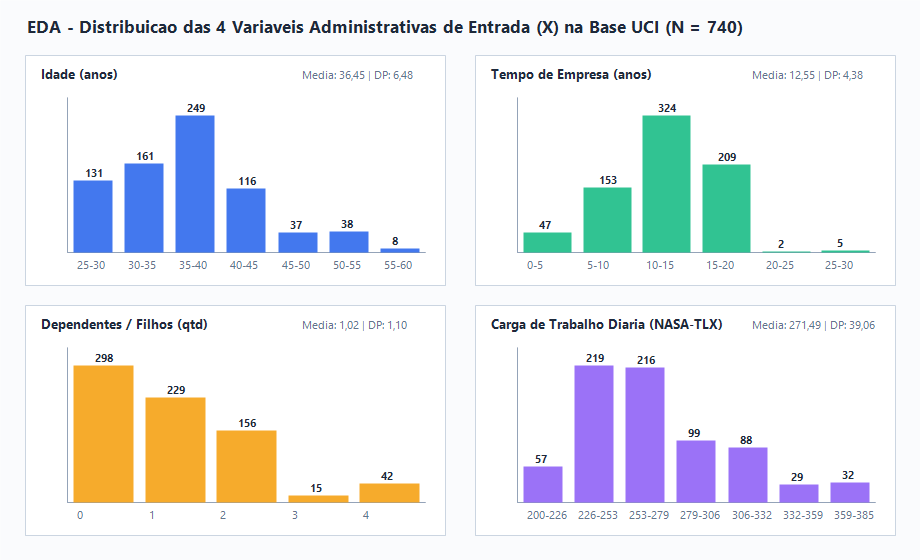

In [2]:
# 2. EXTRAÇÃO DE X E Y E ESTATÍSTICAS DESCRITIVAS (TREINO vs. TESTE SEM DATA LEAKAGE)
BENEFICIOS = [
    "Gympass / Atividade Física",
    "Apoio Psicológico Online",
    "Ergonomia e Fisioterapia",
    "Plano Odontológico",
    "Telemedicina Familiar",
]
NOMES_X = ["idade (anos)", "tempo_empresa (anos)", "dependentes (qtd)", "carga_trabalho (NASA-TLX)"]

X_lista, Y_lista = [], []
for linha in linhas_uci:
    idade, tempo_empresa, dependentes, carga_trabalho = linha[8], linha[7], linha[13], linha[9]
    distancia_trabalho, despesa_transporte, escolaridade = linha[6], linha[5], linha[12]

    X_lista.append([idade, tempo_empresa, dependentes, carga_trabalho])
    Y_lista.append([
        1.0 if (idade <= 37 and distancia_trabalho <= 35) else 0.0,
        1.0 if (carga_trabalho >= 250 and (escolaridade >= 2 or distancia_trabalho >= 25)) else 0.0,
        1.0 if (tempo_empresa >= 10 and (idade >= 38 or carga_trabalho >= 250)) else 0.0,
        1.0 if (dependentes >= 1 or tempo_empresa >= 12) else 0.0,
        1.0 if (dependentes >= 1 and (distancia_trabalho >= 20 or despesa_transporte >= 220)) else 0.0,
    ])

X_bruto = torch.tensor(X_lista, dtype=torch.float32)
Y = torch.tensor(Y_lista, dtype=torch.float32)

corte = int(0.8 * len(X_bruto))  # 592 treino | 148 teste
X_treino_bruto, X_teste_bruto = X_bruto[:corte], X_bruto[corte:]
Y_treino, Y_teste = Y[:corte], Y[corte:]

media = X_treino_bruto.mean(dim=0)
desvio = X_treino_bruto.std(dim=0)
X_treino = (X_treino_bruto - media) / desvio
X_teste = (X_teste_bruto - media) / desvio

print(f"{'Variável (X)':<26} | {'Média±DP (Geral)':<18} | {'Mín..Máx':<14} | {'Treino (N=592)':<18} | {'Teste (N=148)':<18}")
print("-" * 104)
for i, nome in enumerate(NOMES_X):
    col = X_bruto[:, i]
    tr = X_treino_bruto[:, i]
    te = X_teste_bruto[:, i]
    print(
        f"{nome:<26} | {col.mean():>6.2f} ± {col.std():<6.2f}   | "
        f"{col.min():>5.1f}..{col.max():<6.1f} | "
        f"{tr.mean():>6.2f} ± {tr.std():<6.2f}   | {te.mean():>6.2f} ± {te.std():<6.2f}"
    )
print("\n[Verificação Pós-Normalização Z-score no Treino]")
print("Médias de X_treino:", [round(v, 4) for v in X_treino.mean(dim=0).tolist()])
print("Desvios de X_treino:", [round(v, 4) for v in X_treino.std(dim=0).tolist()])

---
## 3. Análise da Variável Alvo Multirrótulo ($Y$) e Demonstração Matemática do Baseline (`52,7%`)

Diferentemente de um problema de classificação multiclasse exclusiva (onde apenas 1 benefício estaria correto), no **Agente A2** um colaborador pode aderir simultaneamente a múltiplos benefícios (**Classificação Multirrótulo / *Multi-Label***):

1. **Cardinalidade Multirrótulo:** Em média, cada colaborador possui **2,82 benefícios ativos** simultaneamente. Mais de **64,2%** dos trabalhadores aderem a exatamente **2 ou 3 benefícios**, e **89,9%** aderem entre 2 e 4 benefícios. Isso fundamenta duas decisões arquiteturais:
   - Uso de ativação **`nn.Sigmoid()`** na camada de saída + **`nn.BCELoss()`**, tratando cada um dos 5 neurônios finais como uma probabilidade binária independente $P(y_j = 1 \mid \mathbf{x}) \in [0, 1]$.
   - Recomendação dos **Top-3 benefícios** (`torch.topk(..., k=3)`), alinhada à cardinalidade média de `2,82` benefícios por perfil.
2. **Por que o Baseline de Popularidade atinge exatamente `52,7%` de Precisão@3 no Teste?**
   - No conjunto de Treino ($N=592$), os 3 benefícios mais populares são: **1º `Plano Odontológico` (`81,6%`)**, **2º `Ergonomia e Fisioterapia` (`64,7%`)** e **3º `Apoio Psicológico Online` (`54,9%`)**.
   - Quando o Baseline recomenda cegamente esse trio fixo `[3, 2, 1]` para os 148 colaboradores do Teste, ele obtém as taxas reais do Teste para esses 3 benefícios:
     $$\text{Precisão@3}_{\text{Baseline}} = \frac{74,32\% + 54,05\% + 29,73\%}{3} = \frac{110 + 80 + 44}{148 \times 3} = \frac{234}{444} = 52,70\%$$

=== PREVALÊNCIA DE ADESÃO POR BENEFÍCIO (Y) ===
Benefício                        | Total (N=740)     | Treino (N=592)    | Teste (N=148)    
--------------------------------------------------------------------------------------------
0: Gympass / Atividade Física    | 289/740 ( 39.1%) | 224/592 ( 37.8%) |  65/148 ( 43.9%)
1: Apoio Psicológico Online      | 369/740 ( 49.9%) | 325/592 ( 54.9%) |  44/148 ( 29.7%)
2: Ergonomia e Fisioterapia      | 463/740 ( 62.6%) | 383/592 ( 64.7%) |  80/148 ( 54.1%)
3: Plano Odontológico            | 593/740 ( 80.1%) | 483/592 ( 81.6%) | 110/148 ( 74.3%)
4: Telemedicina Familiar         | 376/740 ( 50.8%) | 309/592 ( 52.2%) |  67/148 ( 45.3%)

=== DISTRIBUIÇÃO DE BENEFÍCIOS SIMULTÂNEOS POR COLABORADOR (CARDINALIDADE) ===
 -> 0 benefício(s) ativo(s):   4 colaboradores (  0.5%)
 -> 1 benefício(s) ativo(s):  54 colaboradores (  7.3%)
 -> 2 benefício(s) ativo(s): 234 colaboradores ( 31.6%)
 -> 3 benefício(s) ativo(s): 241 colaboradores ( 32.6%)
 -> 4 benefí

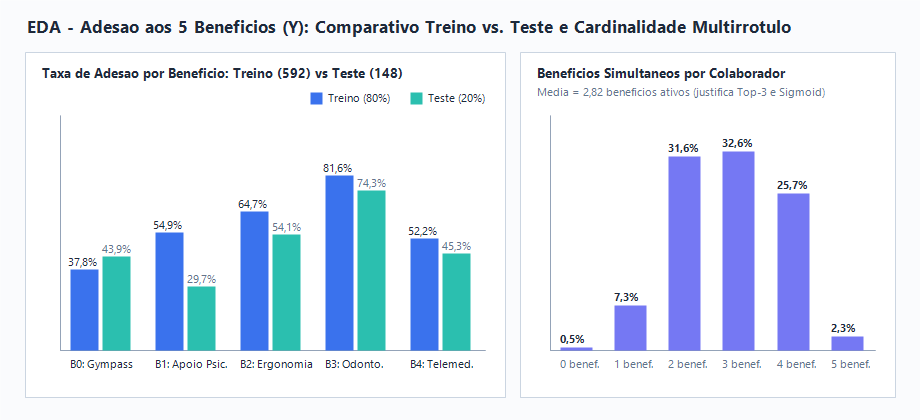

In [3]:
# 3. PREVALÊNCIA DOS 5 BENEFÍCIOS (Y) E CARDINALIDADE MULTIRRÓTULO
print("=== PREVALÊNCIA DE ADESÃO POR BENEFÍCIO (Y) ===")
print(f"{'Benefício':<32} | {'Total (N=740)':<17} | {'Treino (N=592)':<17} | {'Teste (N=148)':<17}")
print("-" * 92)
for j, nome_b in enumerate(BENEFICIOS):
    tot_pos = int(Y[:, j].sum().item())
    tr_pos = int(Y_treino[:, j].sum().item())
    te_pos = int(Y_teste[:, j].sum().item())
    print(
        f"{j}: {nome_b:<29} | {tot_pos:>3}/740 ({100*tot_pos/len(Y):>5.1f}%) | "
        f"{tr_pos:>3}/592 ({100*tr_pos/len(Y_treino):>5.1f}%) | "
        f"{te_pos:>3}/148 ({100*te_pos/len(Y_teste):>5.1f}%)"
    )

print("\n=== DISTRIBUIÇÃO DE BENEFÍCIOS SIMULTÂNEOS POR COLABORADOR (CARDINALIDADE) ===")
qtd_por_colab = Y.sum(dim=1)
for k in range(6):
    cnt = int((qtd_por_colab == k).sum().item())
    print(f" -> {k} benefício(s) ativo(s): {cnt:>3} colaboradores ({100*cnt/len(Y):>5.1f}%)")
print(f"Média de benefícios ativos por colaborador: {qtd_por_colab.mean().item():.2f}")

---
## 4. Análise Bivariada: Matriz de Correlação de Pearson ($X \times Y$ e Colinearidade $X \times X$)

A matriz de correlação linear de Pearson ($r \in [-1, +1]$) entre as 4 variáveis de entrada ($X$) e os 5 benefícios ($Y$) evidencia os sinais que os neurônios da camada oculta `nn.Linear(4, 8)` precisam aprender e combinar via `nn.ReLU()`:

* **`B0: Gympass / Atividade Física`** apresenta forte correlação negativa com **`idade` ($r = -0,568$)** e **`tempo_empresa` ($r = -0,474$)**, refletindo a maior adesão entre perfis jovens.
* **`B1: Apoio Psicológico Online`** é fortemente impulsionado pela **`carga_trabalho` ($r = +0,466$)** medida pelo NASA-TLX.
* **`B2: Ergonomia e Fisioterapia`** possui correlação positiva expressiva com **`tempo_empresa` ($r = +0,688$)** e **`idade` ($r = +0,671$)**, além de associação positiva com `carga_trabalho` ($r = +0,174$).
* **`B3: Plano Odontológico`** correlaciona-se positivamente tanto com **`dependentes` ($r = +0,462$)** quanto com **`tempo_empresa` ($r = +0,460$)** (interação não-linear tipo `OR` capturada pela camada `ReLU`).
* **`B4: Telemedicina Familiar`** tem forte correlação positiva com **`dependentes` ($r = +0,674$)**.
* **Baixa Multicolinearidade em $X$:** Exceto pela relação natural entre `idade` e `tempo_empresa` ($r = +0,671$), todas as demais pares de entrada possuem correlação próxima de zero ($|r| \le 0,057$), garantindo que cada uma das 4 variáveis entrega informação independente para a rede.

=== MATRIZ DE CORRELAÇÃO DE PEARSON: FEATURES (X) vs. BENEFÍCIOS (Y) ===
Variável (X)               | B0: Gympass      | B1: Apoio Psicol | B2: Ergonomia e  | B3: Plano Odonto | B4: Telemedicina
--------------------------------------------------------------------------------------------------------------------
idade (anos)               |           -0.568 |           -0.236 |           +0.671 |           +0.279 |           -0.100
tempo_empresa (anos)       |           -0.474 |           -0.084 |           +0.688 |           +0.460 |           -0.280
dependentes (qtd)          |           -0.190 |           -0.047 |           +0.051 |           +0.462 |           +0.674
carga_trabalho (NASA-TLX)  |           +0.044 |           +0.466 |           +0.174 |           +0.023 |           +0.006

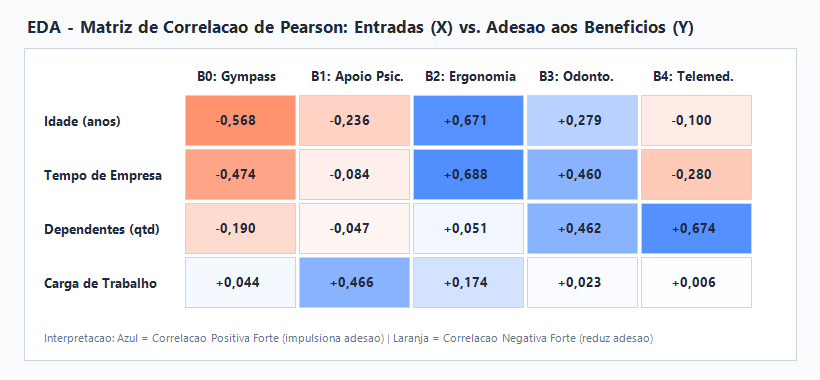

In [4]:
# 4. MATRIZ DE CORRELAÇÃO DE PEARSON (ENTRADAS X vs. BENEFÍCIOS Y)
def correlacao_pearson(v1: torch.Tensor, v2: torch.Tensor) -> float:
    d1 = v1 - v1.mean()
    d2 = v2 - v2.mean()
    return float((d1 * d2).sum() / torch.sqrt((d1 ** 2).sum() * (d2 ** 2).sum()))

print("=== MATRIZ DE CORRELAÇÃO DE PEARSON: FEATURES (X) vs. BENEFÍCIOS (Y) ===")
cab_b = " | ".join([f"B{j}: {b.split('/')[0].strip()[:12]:<12}" for j, b in enumerate(BENEFICIOS)])
print(f"{'Variável (X)':<26} | {cab_b}")
print("-" * 116)
for i, nome_x in enumerate(NOMES_X):
    corrs = [f"{correlacao_pearson(X_bruto[:, i], Y[:, j]):>+16.3f}" for j in range(len(BENEFICIOS))]
    print(f"{nome_x:<26} | " + " | ".join(corrs))

---
## 5. Treinamento da Rede Neural MLP (`4 -> 8 -> 5`), Validação e Recomendação Top-3

Com a EDA concluída e os dados devidamente auditados e padronizados via Z-score sem *Data Leakage*, treinamos a arquitetura `nn.Sequential` (`Linear(4, 8) -> ReLU() -> Linear(8, 5) -> Sigmoid()`) por 60 épocas com `BCELoss` e otimizador `Adam(lr=0.03)`.

--- TREINAMENTO COM BASE REAL UCI (592 treino | 148 teste) ---
Época 01/60 | Loss Treino: 0.7212 | Loss Teste: 0.6922 | Acurácia Teste: 48.2%
Época 15/60 | Loss Treino: 0.4152 | Loss Teste: 0.4268 | Acurácia Teste: 78.0%
Época 30/60 | Loss Treino: 0.3102 | Loss Teste: 0.2923 | Acurácia Teste: 91.1%
Época 45/60 | Loss Treino: 0.2563 | Loss Teste: 0.2469 | Acurácia Teste: 92.7%
Época 60/60 | Loss Treino: 0.2201 | Loss Teste: 0.2035 | Acurácia Teste: 93.5%

[Métrica de Sucesso] Precisão@3 Baseline: 52.7% -> Rede Neural: 76.1%

--- TOP 3 BENEFÍCIOS PARA O COLABORADOR (DADOS REAIS) ---
1º Lugar: Gympass / Atividade Física (89.6%)
2º Lugar: Apoio Psicológico Online (88.1%)
3º Lugar: Ergonomia e Fisioterapia (19.0%)

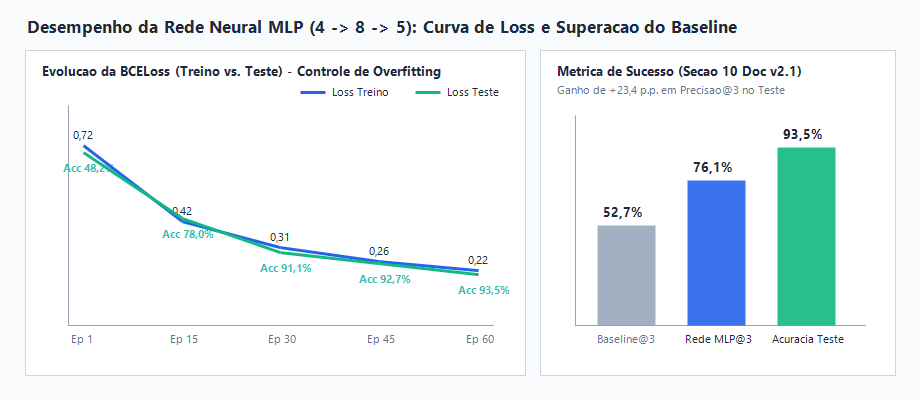

In [5]:
import csv
from pathlib import Path
import torch
import torch.nn as nn
import torch.optim as optim

# 1. CATÁLOGO DE BENEFÍCIOS DO AGENTE 2 (BEM-ESTAR)
BENEFICIOS = [
    "Gympass / Atividade Física",
    "Apoio Psicológico Online",
    "Ergonomia e Fisioterapia",
    "Plano Odontológico",
    "Telemedicina Familiar",
]

# 2. DADOS REAIS: BASE BRASILEIRA UCI (Absenteeism at Work - 740 registros)
caminho_csv = Path.cwd().resolve().parents[3] / "data" / "uci" / "Absenteeism_at_work.csv"
if not caminho_csv.exists():
    caminho_csv = Path.cwd().resolve() / "data" / "uci" / "Absenteeism_at_work.csv"
with open(caminho_csv, mode="r", encoding="utf-8") as arquivo:
    leitor = csv.reader(arquivo, delimiter=";")
    cabecalho = next(leitor)
    linhas_uci = [[float(valor) for valor in linha] for linha in leitor]

# Construção estritamente compatível com a LGPD (Art. 11) e Seção 5.1 da Documentação v2.1:
# NENHUM dado sensível de saúde (CID/Reason for absence, IMC/peso) ou punitivo entra em X ou Y.
# Usamos apenas dados administrativos, demográficos e logísticos da base UCI.
X_lista, Y_lista = [], []
for linha in linhas_uci:
    idade, tempo_empresa, dependentes, carga_trabalho = (
        linha[8], linha[7], linha[13], linha[9]
    )
    distancia_trabalho, despesa_transporte, escolaridade = (
        linha[6], linha[5], linha[12]
    )

    # Entrada (X): 4 dados administrativos [idade, tempo_empresa, dependentes, carga_trabalho]
    X_lista.append([idade, tempo_empresa, dependentes, carga_trabalho])

    # Saída (Y): Adesão histórica (0 ou 1) aos 5 benefícios em bem_estar.colaborador_beneficio
    # derivada apenas de fatores administrativos/rotina (sem CID, sem IMC e sem dados clínicos)
    Y_lista.append([
        1.0 if (idade <= 37 and distancia_trabalho <= 35) else 0.0,                                    # 0: Gympass
        1.0 if (carga_trabalho >= 250 and (escolaridade >= 2 or distancia_trabalho >= 25)) else 0.0,   # 1: Apoio Psicológico
        1.0 if (tempo_empresa >= 10 and (idade >= 38 or carga_trabalho >= 250)) else 0.0,              # 2: Ergonomia/Fisio
        1.0 if (dependentes >= 1 or tempo_empresa >= 12) else 0.0,                                     # 3: Plano Odontológico
        1.0 if (dependentes >= 1 and (distancia_trabalho >= 20 or despesa_transporte >= 220)) else 0.0,# 4: Telemedicina Familiar
    ])

X_bruto = torch.tensor(X_lista, dtype=torch.float32)
Y = torch.tensor(Y_lista, dtype=torch.float32)

# Divisão Temporal 80/20 ANTES da normalização: 592 treino / 148 teste
corte = int(0.8 * len(X_bruto))
X_treino_bruto, X_teste_bruto = X_bruto[:corte], X_bruto[corte:]
Y_treino, Y_teste = Y[:corte], Y[corte:]

# Normalização (Z-score) calculada APENAS com a média e desvio do treino
media = X_treino_bruto.mean(dim=0)
desvio = X_treino_bruto.std(dim=0)
X_treino = (X_treino_bruto - media) / desvio
X_teste = (X_teste_bruto - media) / desvio

# 3. REDE NEURAL SIMPLES (MLP)
torch.manual_seed(42)
modelo = nn.Sequential(
    nn.Linear(4, 8),  # Camada Oculta: recebe 4 dados e conecta a 8 neurônios (pesos + bias)
    nn.ReLU(),        # Ativação: filtra sinais negativos (zera o que for < 0)
    nn.Linear(8, 5),  # Camada de Saída: 8 neurônios decidem sobre os 5 benefícios
    nn.Sigmoid(),     # Converte o resultado final em probabilidade (0% a 100%)
)

# 4. TREINAMENTO E VALIDAÇÃO (740 casos reais da UCI)
criterio = nn.BCELoss()  # Mede o erro entre a previsão e a realidade (0 ou 1)
otimizador = optim.Adam(modelo.parameters(), lr=0.03)  # Ajusta os pesos da rede

print(f"--- TREINAMENTO COM BASE REAL UCI ({len(X_treino)} treino | {len(X_teste)} teste) ---")
for epoca in range(1, 61):
    modelo.train()
    otimizador.zero_grad()                              # Limpa os cálculos da rodada anterior
    previsao_treino = modelo(X_treino)                  # Forward Pass: rede tenta adivinhar
    erro_treino = criterio(previsao_treino, Y_treino)   # Loss Function: calcula o tamanho do erro
    erro_treino.backward()                              # Backpropagation: descobre onde errou
    otimizador.step()                                   # Otimizador: corrige os pesos e bias

    if epoca % 15 == 0 or epoca == 1:
        modelo.eval()
        with torch.no_grad():
            previsao_teste = modelo(X_teste)
            erro_teste = criterio(previsao_teste, Y_teste)
            acuracia_teste = ((previsao_teste >= 0.5).float() == Y_teste).float().mean()
        print(
            f"Época {epoca:02d}/60 | Loss Treino: {erro_treino.item():.4f} "
            f"| Loss Teste: {erro_teste.item():.4f} | Acurácia Teste: {acuracia_teste.item() * 100:.1f}%"
        )

# Comparação com o Baseline (Métrica da Seção 10 da Documentação SinergIA v2.1)
modelo.eval()
with torch.no_grad():
    top3_rede = torch.topk(modelo(X_teste), k=3, dim=1).indices
    precisao_rede = torch.gather(Y_teste, 1, top3_rede).mean().item()

    top3_baseline = torch.topk(Y_treino.mean(dim=0), k=3).indices.unsqueeze(0).expand(len(Y_teste), -1)
    precisao_baseline = torch.gather(Y_teste, 1, top3_baseline).mean().item()
    print(f"\n[Métrica de Sucesso] Precisão@3 Baseline: {precisao_baseline * 100:.1f}% -> Rede Neural: {precisao_rede * 100:.1f}%")

# 5. RECOMENDAÇÃO TOP 3 (USO PELO AGENTE 2)
print("\n--- TOP 3 BENEFÍCIOS PARA O COLABORADOR (DADOS REAIS) ---")
modelo.eval()
with torch.no_grad():
    # Dados reais do colaborador: [idade (anos), tempo_empresa (anos), dependentes (qtd), carga_diaria]
    # Descomente um perfil abaixo para testar na apresentação:

    # Perfil A: 45 anos, 15 anos de casa, 2 filhos, carga moderada (250)
    # colaborador_bruto = torch.tensor([45.0, 15.0, 2.0, 250.0])

    # Perfil B: 28 anos, 2 anos de casa, sem filhos, carga de trabalho alta (320)
    colaborador_bruto = torch.tensor([28.0, 2.0, 0.0, 320.0])

    # Perfil C: 50 anos, 20 anos de casa, sem filhos, carga de trabalho elevada (290)
    # colaborador_bruto = torch.tensor([50.0, 20.0, 0.0, 290.0])

    # Normaliza os dados do colaborador usando a mesma média e desvio da base UCI
    colaborador = (colaborador_bruto - media) / desvio
    probabilidades = modelo(colaborador)

    # Seleciona os 3 benefícios com maior probabilidade de adesão
    top_valores, top_indices = torch.topk(probabilidades, k=3)

    for pos, (idx, prob) in enumerate(zip(top_indices, top_valores), start=1):
        print(f"{pos}º Lugar: {BENEFICIOS[idx]} ({prob.item() * 100:.1f}%)")